# Logistic Regression — Acoustic Event Classification
### Sonobuoy Sound Detective: Offline Underwater Acoustic Event Detection
**Workspace Folder:** `01_person1_lr_and_knn/`  
**Algorithm Identifier:** `logistic_regression`

---

## 1. Algorithm Overview & Theoretical Foundation
**Multinomial Logistic Regression** with L2 regularization is our primary linear reference.
It estimates class posterior distributions via the softmax function:
$$P(y = c \mid \mathbf{x}) = \frac{e^{\mathbf{w}_c^T \mathbf{x} + b_c}}{\sum_{j=1}^K e^{\mathbf{w}_j^T \mathbf{x} + b_j}}$$
Regularization parameter $C$ controls the trade-off between margin width and empirical cross-entropy loss.

This self-contained notebook performs:
1. Loading the shared acoustic feature matrix (`../data/features/features.parquet`).
2. Stratified Train / Validation / Test splitting (80% / 10% / 10%).
3. Feature standardization with `StandardScaler`.
4. Hyperparameter tuning & 5-Fold Stratified Cross-Validation.
5. Held-out Test Set evaluation (Accuracy, Macro Precision, Macro Recall, Macro F1, Multi-Class ROC-AUC).
6. Generating and saving **Confusion Matrix**, **ROC Curves**, and **Interpretability Plots** into `plots/`.
7. Exporting the final trained model, scaler, and evaluation metrics into `models/` for the final comparison showdown!

In [7]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, log_loss,
    precision_recall_curve, precision_score, recall_score, roc_auc_score,
    roc_curve, auc,
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedGroupKFold, cross_validate, learning_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
sns.set_theme(style="whitegrid")
Path("models").mkdir(exist_ok=True)
Path("plots").mkdir(exist_ok=True)


## 2. Load Shared Acoustic Features and Selected Descriptors

##### 2.1 Load Dataset


In [8]:
features_path = Path("../data/features/features.csv")
selected_path = Path("../data/features/selected_features.json")
if not features_path.exists():
    raise FileNotFoundError(f"Feature table not found: {features_path.resolve()}")
if not selected_path.exists():
    raise FileNotFoundError(f"Selected-feature list not found: {selected_path.resolve()}")

df = pd.read_csv(features_path)
selected_payload = json.loads(selected_path.read_text(encoding="utf-8"))
feature_cols = selected_payload.get("selected_features", selected_payload) if isinstance(selected_payload, dict) else selected_payload
if not isinstance(feature_cols, list) or not feature_cols:
    raise ValueError("selected_features.json does not contain a non-empty feature list")
required_cols = set(feature_cols) | {"label", "split", "source_clip_id"}
missing_required = sorted(required_cols - set(df.columns))
if missing_required:
    raise ValueError(f"Required columns missing from feature table: {missing_required}")
print("Dataset shape:", df.shape)
print("Selected feature count:", len(feature_cols))


Dataset shape: (3579, 221)
Selected feature count: 66


##### 2.2 Select Input Features and Target

In [9]:
X = df.loc[:, feature_cols].copy()
y_text = df["label"].copy()
print("Input matrix shape:", X.shape)
print("Target classes:", sorted(y_text.unique().tolist()))


Input matrix shape: (3579, 66)
Target classes: ['ambient', 'unknown', 'vessel_like']


## 3. Stratified Train / Validation / Test Splitting and Feature Scaling

##### 3.1 Prepare Dataset Splits

In [10]:
official_splits = {"train", "val", "test"}
if not official_splits.issubset(set(df["split"].dropna().unique())):
    raise ValueError(f"Official train/val/test split labels are incomplete: {sorted(df['split'].unique())}")
train_mask = df["split"].eq("train")
val_mask = df["split"].eq("val")
test_mask = df["split"].eq("test")
X_train_raw, X_val_raw, X_test_raw = X.loc[train_mask], X.loc[val_mask], X.loc[test_mask]
y_train_text, y_val_text, y_test_text = y_text.loc[train_mask], y_text.loc[val_mask], y_text.loc[test_mask]
groups_train = df.loc[train_mask, "source_clip_id"]
print("Train:", X_train_raw.shape, "Validation:", X_val_raw.shape, "Test:", X_test_raw.shape)


Train: (2756, 66) Validation: (341, 66) Test: (482, 66)


##### 3.2 Separate Features and Target

In [11]:
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_text)
y_val = label_encoder.transform(y_val_text)
y_test = label_encoder.transform(y_test_text)
classes = label_encoder.classes_.tolist()
print("Classes:", classes)


Classes: ['ambient', 'unknown', 'vessel_like']


##### 3.3 Check Split Information
Display split shapes, class counts, and source-clip overlap. Every official split pair should have zero overlapping source clips.

In [12]:
split_counts = pd.crosstab(df["label"], df["split"]).reindex(columns=["train", "val", "test"], fill_value=0)
print(split_counts)
clip_sets = {name: set(df.loc[df["split"].eq(name), "source_clip_id"]) for name in official_splits}
for first, second in [("train", "val"), ("train", "test"), ("val", "test")]:
    overlap = clip_sets[first] & clip_sets[second]
    print(f"{first}/{second} overlapping source clips: {len(overlap)}")


split        train  val  test
label                        
ambient        153   19    20
unknown         66    8     9
vessel_like   2537  314   453
train/val overlapping source clips: 0
train/test overlapping source clips: 0
val/test overlapping source clips: 0


##### 3.4 Feature Standardization
A `StandardScaler` is required for Logistic Regression.

In [14]:
print("Standardization will be fitted inside each cross-validation training fold.")


Standardization will be fitted inside each cross-validation training fold.


##### 3.5 Create Preprocessing Pipeline

In [15]:
lr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(
        penalty="l2",
        solver="lbfgs",
        max_iter=2000,
        random_state=RANDOM_SEED,
    )),
])

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_SEED,
)

print(lr_pipeline)


Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('lr',
                 LogisticRegression(max_iter=2000, penalty='l2',
                                    random_state=42))])


## 4. Hyperparameter Tuning and Cross-Validation for Logistic Regression

##### 4.1 Define the Baseline Model

In [16]:
dummy = DummyClassifier(strategy="most_frequent")
dummy_result = cross_validate(dummy, X_train_raw, y_train, cv=cv, groups=groups_train, scoring="f1_macro", n_jobs=-1)
base_result = cross_validate(lr_pipeline.set_params(lr__C=1.0, lr__class_weight=None), X_train_raw, y_train, cv=cv, groups=groups_train, scoring="f1_macro", n_jobs=-1)
print(f"Dummy grouped CV macro F1: {dummy_result['test_score'].mean():.6f} +/- {dummy_result['test_score'].std():.6f}")
print(f"Baseline Logistic Regression grouped CV macro F1: {base_result['test_score'].mean():.6f} +/- {base_result['test_score'].std():.6f}")


Dummy grouped CV macro F1: 0.319542 +/- 0.000237
Baseline Logistic Regression grouped CV macro F1: 0.914574 +/- 0.021005


##### 4.2 Experiment 1: Tune Regularization Parameter C
Evaluate six dynamically generated regularization strengths and record mean and standard deviation of grouped-CV macro F1.

      C class_weight  mean_cv_macro_f1  std_cv_macro_f1  mean_train_macro_f1
  0.001         None          0.607206         0.010997             0.607996
  0.010         None          0.836701         0.041775             0.862576
  0.100         None          0.921485         0.017486             0.955002
  1.000         None          0.914574         0.021005             0.987299
 10.000         None          0.887680         0.036730             0.994101
100.000         None          0.877329         0.046901             0.998046


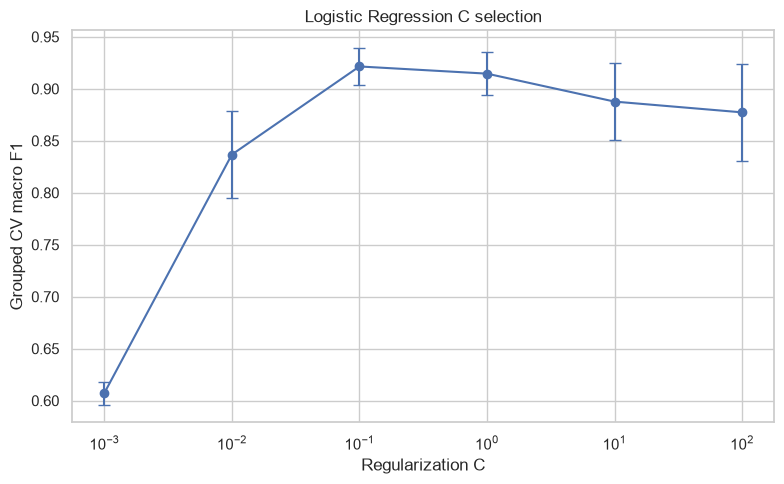

In [17]:
c_values = [0.001, 0.01, 0.1, 1, 10, 100]
c_rows = []
for c_value in c_values:
    estimator = lr_pipeline.set_params(lr__C=c_value, lr__class_weight=None)
    result = cross_validate(estimator, X_train_raw, y_train, cv=cv, groups=groups_train, scoring="f1_macro", n_jobs=-1, return_train_score=True)
    c_rows.append({"C": c_value, "class_weight": "None", "mean_cv_macro_f1": result["test_score"].mean(), "std_cv_macro_f1": result["test_score"].std(), "mean_train_macro_f1": result["train_score"].mean()})
c_experiment = pd.DataFrame(c_rows)
print(c_experiment.to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(c_experiment["C"], c_experiment["mean_cv_macro_f1"], yerr=c_experiment["std_cv_macro_f1"], marker="o", capsize=4)
ax.set_xscale("log"); ax.set_xlabel("Regularization C"); ax.set_ylabel("Grouped CV macro F1"); ax.set_title("Logistic Regression C selection")
fig.tight_layout(); fig.savefig("plots/logistic_c_selection_curve.png", dpi=200); plt.show(); plt.close(fig)


##### 4.3 Experiment 2: Compare Class Weighting

class_weight  mean_cv_macro_f1  std_cv_macro_f1
        None          0.914574         0.021005
    balanced          0.885023         0.026883


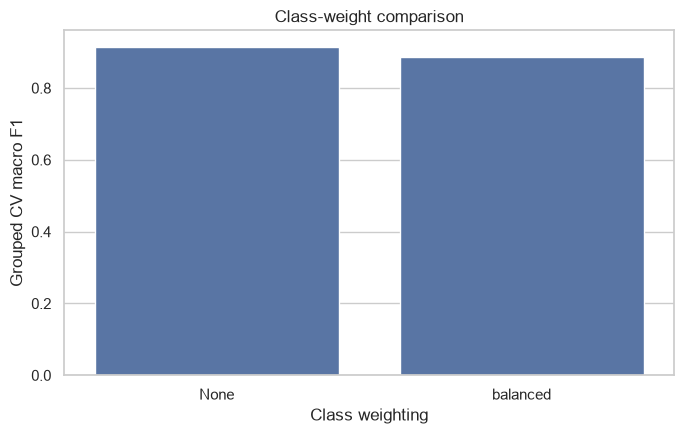

In [18]:
weight_rows = []
for weight in [None, "balanced"]:
    result = cross_validate(lr_pipeline.set_params(lr__C=1.0, lr__class_weight=weight), X_train_raw, y_train, cv=cv, groups=groups_train, scoring="f1_macro", n_jobs=-1)
    weight_rows.append({"class_weight": "None" if weight is None else weight, "mean_cv_macro_f1": result["test_score"].mean(), "std_cv_macro_f1": result["test_score"].std()})
weight_experiment = pd.DataFrame(weight_rows)
print(weight_experiment.to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 4.5)); sns.barplot(data=weight_experiment, x="class_weight", y="mean_cv_macro_f1", ax=ax, errorbar=None)
ax.set_xlabel("Class weighting"); ax.set_ylabel("Grouped CV macro F1"); ax.set_title("Class-weight comparison")
fig.tight_layout(); fig.savefig("plots/logistic_class_weight_comparison.png", dpi=200); plt.show(); plt.close(fig)


##### 4.4 Perform Cross-Validation

In [19]:
param_grid = {"lr__C": c_values, "lr__class_weight": [None, "balanced"]}
search = GridSearchCV(lr_pipeline, param_grid=param_grid, scoring="f1_macro", cv=cv, n_jobs=-1, refit=True, return_train_score=True)
search.fit(X_train_raw, y_train, groups=groups_train)
tuning_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
tuning_results.to_csv("models/logistic_regression_tuning_results.csv", index=False)
print("Grid configurations:", len(tuning_results))
print(tuning_results[["param_lr__C", "param_lr__class_weight", "mean_test_score", "std_test_score", "rank_test_score"]].to_string(index=False))


Grid configurations: 12
 param_lr__C param_lr__class_weight  mean_test_score  std_test_score  rank_test_score
       0.100                    NaN         0.921485        0.017486                1
       1.000                    NaN         0.914574        0.021005                2
      10.000                    NaN         0.887680        0.036730                3
       1.000               balanced         0.885023        0.026883                4
      10.000               balanced         0.883535        0.034275                5
     100.000                    NaN         0.877329        0.046901                6
     100.000               balanced         0.872389        0.046591                7
       0.100               balanced         0.838038        0.037813                8
       0.010                    NaN         0.836701        0.041775                9
       0.010               balanced         0.770511        0.049416               10
       0.001               bal

d:\ML\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


##### 4.5 Select the Best Model
Select the configuration with the highest grouped-CV macro F1 and report its measured parameters and score.

In [20]:
best_model = search.best_estimator_
best_params = search.best_params_
best_cv_score = float(search.best_score_)
print("Best parameters:", best_params)
print(f"Best grouped CV macro F1: {best_cv_score:.6f}")

Best parameters: {'lr__C': 0.1, 'lr__class_weight': None}
Best grouped CV macro F1: 0.921485


##### 4.6 Learning Curve

 train_segments  train_macro_f1  cv_macro_f1   cv_std
            441        0.949931     0.386792 0.024979
            882        0.930228     0.384399 0.023825
           1323        0.915554     0.380646 0.028742
           1764        0.739521     0.530758 0.131414
           2205        0.955002     0.921485 0.017486


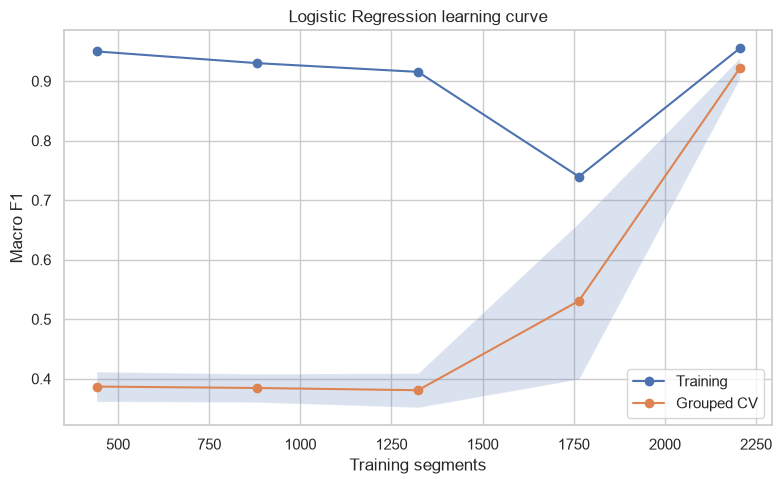

In [21]:
curve_sizes, curve_train, curve_valid = learning_curve(best_model, X_train_raw, y_train, groups=groups_train, cv=cv, scoring="f1_macro", n_jobs=-1, train_sizes=np.linspace(0.2, 1.0, 5))
learning_curve_df = pd.DataFrame({"train_segments": curve_sizes, "train_macro_f1": curve_train.mean(axis=1), "cv_macro_f1": curve_valid.mean(axis=1), "cv_std": curve_valid.std(axis=1)})
print(learning_curve_df.to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 5)); ax.plot(curve_sizes, learning_curve_df["train_macro_f1"], marker="o", label="Training"); ax.plot(curve_sizes, learning_curve_df["cv_macro_f1"], marker="o", label="Grouped CV"); ax.fill_between(curve_sizes, learning_curve_df["cv_macro_f1"]-learning_curve_df["cv_std"], learning_curve_df["cv_macro_f1"]+learning_curve_df["cv_std"], alpha=.2); ax.set_xlabel("Training segments"); ax.set_ylabel("Macro F1"); ax.set_title("Logistic Regression learning curve"); ax.legend()
fig.tight_layout(); fig.savefig("plots/logistic_learning_curve.png", dpi=200); plt.show(); plt.close(fig)


## 5. Evaluate Optimal Logistic Regression on Held-Out Test Set

##### 5.1 Train the  Model

In [22]:
train_start = time.perf_counter()
best_model.fit(X_train_raw, y_train)
training_time_seconds = time.perf_counter() - train_start
print(f"Training time: {training_time_seconds:.4f} seconds")


Training time: 0.0572 seconds


d:\ML\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


##### 5.2 Evaluate on Validation Data

In [23]:
def metric_dict(y_true, pred, prob):
    return {
        "accuracy": float(accuracy_score(y_true, pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, pred)),
        "macro_precision": float(precision_score(y_true, pred, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, pred, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, pred, average="macro")),
        "roc_auc_macro": float(roc_auc_score(y_true, prob, multi_class="ovr", average="macro")),
        "log_loss": float(log_loss(y_true, prob, labels=list(range(len(classes))))),
    }
val_pred = best_model.predict(X_val_raw); val_prob = best_model.predict_proba(X_val_raw)
val_metrics = metric_dict(y_val, val_pred, val_prob)
print(json.dumps(val_metrics, indent=2))


{
  "accuracy": 0.9794721407624634,
  "balanced_accuracy": 0.9596044250754274,
  "macro_precision": 0.9220988015200233,
  "macro_recall": 0.9596044250754274,
  "macro_f1": 0.9393560975609755,
  "roc_auc_macro": 0.9961878526279699,
  "log_loss": 0.06301117732135039
}


##### 5.3 Evaluate on the Test Dataset

In [24]:
prediction_start = time.perf_counter()
test_pred = best_model.predict(X_test_raw)
test_prob = best_model.predict_proba(X_test_raw)
prediction_time_seconds = time.perf_counter() - prediction_start
latency_ms = prediction_time_seconds / len(X_test_raw) * 1000
print(f"Processed {len(X_test_raw)} test samples in {prediction_time_seconds:.4f} seconds ({latency_ms:.4f} ms/sample)")


Processed 482 test samples in 0.0043 seconds (0.0088 ms/sample)


##### 5.4 Calculate Evaluation Metrics
Calculate accuracy, macro metrics, balanced accuracy, multiclass one-vs-rest ROC-AUC, and log loss from generated predictions and probabilities.

In [24]:
test_metrics = metric_dict(y_test, test_pred, test_prob)
print(json.dumps(test_metrics, indent=2))


{
  "accuracy": 0.9730290456431535,
  "balanced_accuracy": 0.8337380426784401,
  "macro_precision": 0.86099965188076,
  "macro_recall": 0.8337380426784401,
  "macro_f1": 0.842111011178209,
  "roc_auc_macro": 0.9923963261343837,
  "log_loss": 0.13159537002042537
}


### 5.5 Prepare Final Evaluation Table

In [25]:
evaluation_table = pd.DataFrame({"metric": list(val_metrics), "validation": list(val_metrics.values()), "test": [test_metrics[name] for name in val_metrics]})
print(evaluation_table.to_string(index=False))


           metric  validation     test
         accuracy    0.979472 0.973029
balanced_accuracy    0.959604 0.833738
  macro_precision    0.922099 0.861000
     macro_recall    0.959604 0.833738
         macro_f1    0.939356 0.842111
    roc_auc_macro    0.996188 0.992396
         log_loss    0.063011 0.131595


##### 5.6 Training Time and Prediction Time

In [26]:
runtime_metrics = {"training_time_seconds": float(training_time_seconds), "prediction_time_seconds": float(prediction_time_seconds), "latency_ms": float(latency_ms), "test_segments": int(len(X_test_raw))}
print(json.dumps(runtime_metrics, indent=2))


{
  "training_time_seconds": 0.03578039999410976,
  "prediction_time_seconds": 0.0033894999942276627,
  "latency_ms": 0.007032157664372744,
  "test_segments": 482
}


## 6. Confusion Matrix and Multi-Class ROC Curves

##### 6.1 Generate Predictions

In [27]:
print("Prediction matrix:", test_prob.shape)


Prediction matrix: (482, 3)


##### 6.2 Classification Report

In [28]:
print(classification_report(y_test, test_pred, target_names=classes, digits=3, zero_division=0))


              precision    recall  f1-score   support

     ambient      0.739     0.850     0.791        20
     unknown      0.857     0.667     0.750         9
 vessel_like      0.987     0.985     0.986       453

    accuracy                          0.973       482
   macro avg      0.861     0.834     0.842       482
weighted avg      0.974     0.973     0.973       482



##### 6.3 Confusion Matrix

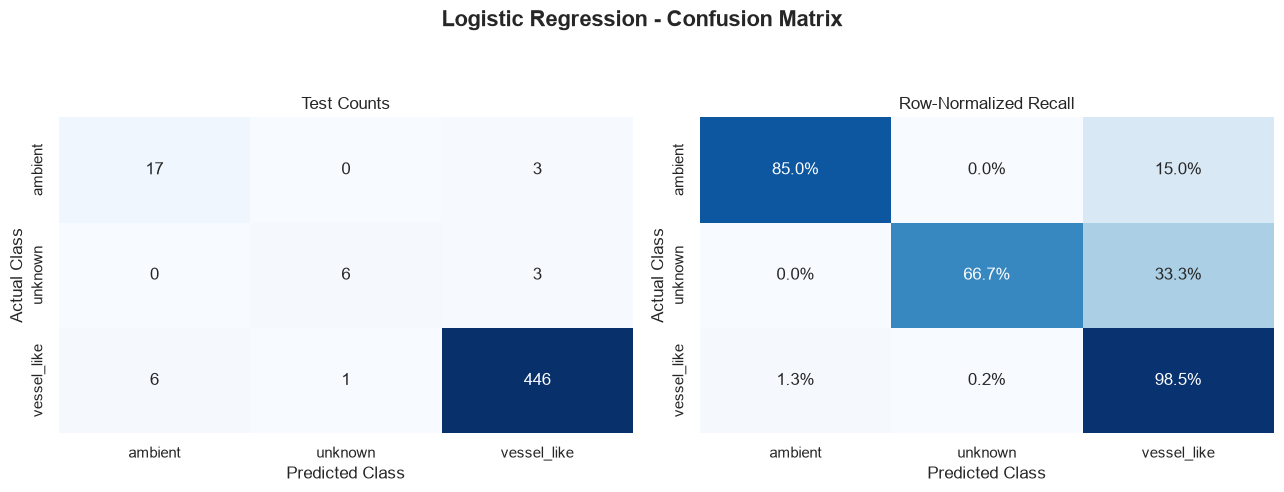

In [25]:
cm = confusion_matrix(
    y_test,
    test_pred,
    labels=list(range(len(classes)))
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Main heading
fig.suptitle(
    "Logistic Regression - Confusion Matrix",
    fontsize=16,
    fontweight="bold"
)

# First graph: Test counts
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=classes,
    yticklabels=classes,
    ax=axes[0]
)

axes[0].set_title("Test Counts")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Actual Class")

# Second graph: Normalized confusion matrix
cm_norm = cm / np.maximum(
    cm.sum(axis=1, keepdims=True), 1
)

sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    cbar=False,
    xticklabels=classes,
    yticklabels=classes,
    ax=axes[1]
)

axes[1].set_title("Row-Normalized Recall")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("Actual Class")

fig.tight_layout(rect=[0, 0, 1, 0.92])

fig.savefig(
    "plots/confusion_matrix_logistic_regression.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

##### 6.4 Multi-Class ROC Curves

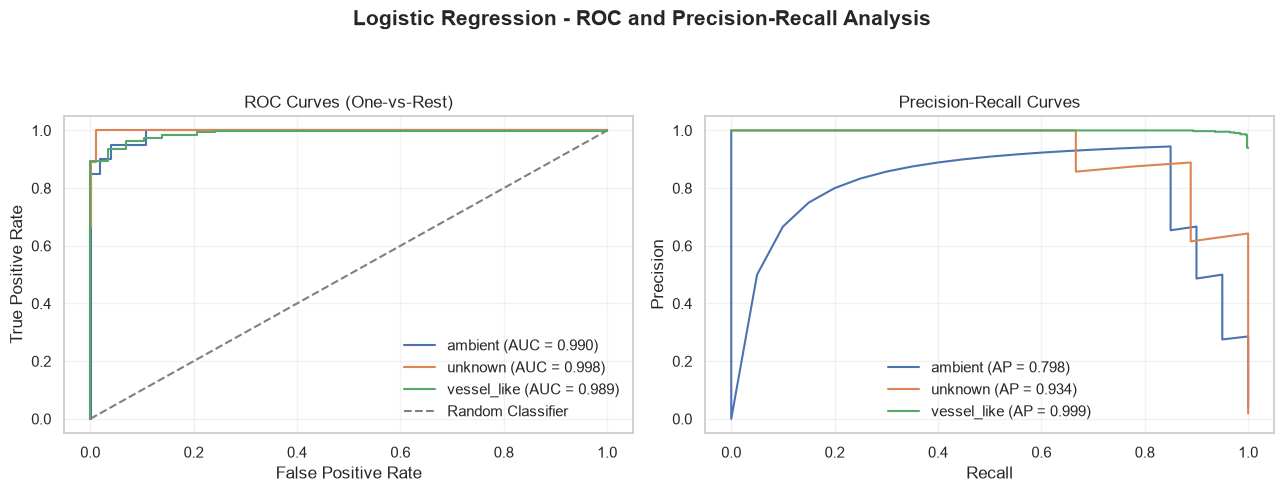


Logistic Regression - ROC and Precision-Recall Results
      class  roc_auc  average_precision
    ambient 0.989719           0.797864
    unknown 0.998356           0.934083
vessel_like 0.989115           0.999296


In [26]:
roc_rows = []

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for class_index, class_name in enumerate(classes):
    binary = (y_test == class_index).astype(int)

    fpr, tpr, _ = roc_curve(binary, test_prob[:, class_index])
    precision, recall, _ = precision_recall_curve(
        binary, test_prob[:, class_index]
    )

    class_auc = auc(fpr, tpr)
    class_ap = average_precision_score(binary, test_prob[:, class_index])

    roc_rows.append({
        "class": class_name,
        "roc_auc": float(class_auc),
        "average_precision": float(class_ap)
    })

    axes[0].plot(
        fpr, tpr,
        label=f"{class_name} (AUC = {class_auc:.3f})"
    )

    axes[1].plot(
        recall, precision,
        label=f"{class_name} (AP = {class_ap:.3f})"
    )

# ROC curve
axes[0].plot([0, 1], [0, 1], "--", color="gray",
             label="Random Classifier")
axes[0].set_title("ROC Curves (One-vs-Rest)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")

# Precision-Recall curve
axes[1].set_title("Precision-Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")

# Common formatting
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)

# Main heading
fig.suptitle(
    "Logistic Regression - ROC and Precision-Recall Analysis",
    fontsize=15,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.92])

fig.savefig(
    "plots/roc_pr_curves_logistic_regression.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Display evaluation results
print("\nLogistic Regression - ROC and Precision-Recall Results")
print(pd.DataFrame(roc_rows).to_string(index=False))

## 7. Model Interpretability and Feature Importance

### 7.1 Extract Model Coefficients
Extract class-specific coefficients from the fitted pipeline. Coefficients operate on standardized features and indicate the direction and strength of linear association.

In [30]:
lr_model = best_model.named_steps["lr"]
coef_df = pd.DataFrame(lr_model.coef_, index=classes, columns=feature_cols)
print("Coefficient matrix shape:", coef_df.shape)


Coefficient matrix shape: (3, 66)


##### 7.2 Feature Importance Using Coefficients

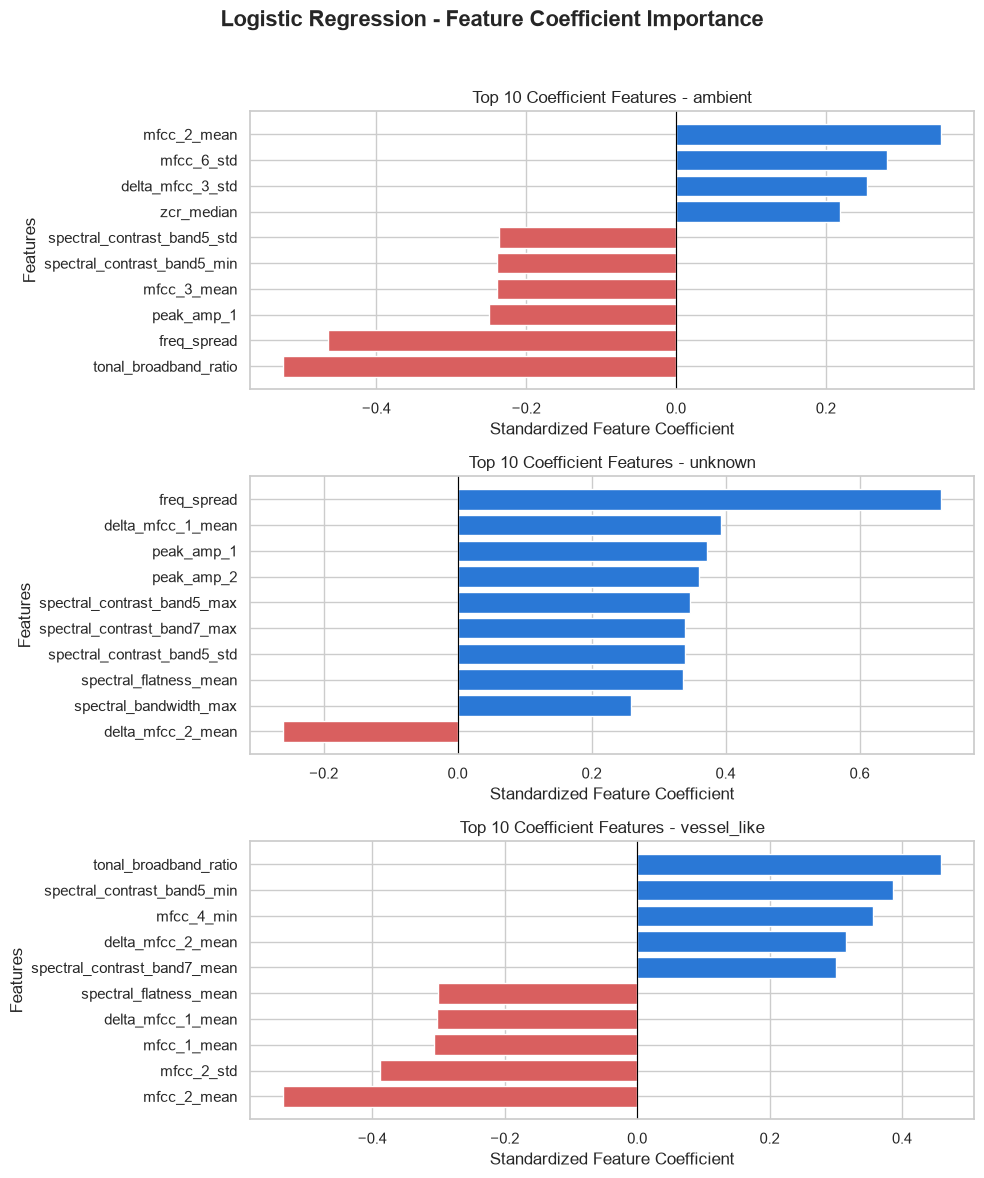


Logistic Regression - Coefficient Importance Results
      class                      feature  coefficient  absolute_coefficient
    ambient        tonal_broadband_ratio    -0.524225              0.524225
    ambient                  freq_spread    -0.464961              0.464961
    ambient                  mfcc_2_mean     0.353929              0.353929
    ambient                   mfcc_6_std     0.281318              0.281318
    ambient             delta_mfcc_3_std     0.254841              0.254841
    ambient                   peak_amp_1    -0.249558              0.249558
    ambient                  mfcc_3_mean    -0.239312              0.239312
    ambient  spectral_contrast_band5_min    -0.238347              0.238347
    ambient  spectral_contrast_band5_std    -0.236557              0.236557
    ambient                   zcr_median     0.218482              0.218482
    unknown                  freq_spread     0.721721              0.721721
    unknown            delta_mfcc_

In [31]:
coef_rows = []

for class_name in classes:
    values = coef_df.loc[class_name]
    strongest = values.abs().sort_values(ascending=False).head(10).index

    for feature in strongest:
        coef_rows.append({
            "class": class_name,
            "feature": feature,
            "coefficient": float(values[feature]),
            "absolute_coefficient": float(abs(values[feature]))
        })

coef_importance = pd.DataFrame(coef_rows)

fig, axes = plt.subplots(
    len(classes), 1,
    figsize=(10, 4 * len(classes))
)

axes = np.atleast_1d(axes)

for ax, class_name in zip(axes, classes):
    part = coef_importance[
        coef_importance["class"].eq(class_name)
    ].sort_values("coefficient")

    ax.barh(
        part["feature"],
        part["coefficient"],
        color=np.where(
            part["coefficient"] >= 0,
            "#2a78d6",
            "#d95f5f"
        )
    )

    ax.set_title(f"Top 10 Coefficient Features - {class_name}")
    ax.set_xlabel("Standardized Feature Coefficient")
    ax.set_ylabel("Features")
    ax.axvline(0, color="black", linewidth=0.8)

# Main heading
fig.suptitle(
    "Logistic Regression - Feature Coefficient Importance",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.96])

fig.savefig(
    "plots/logistic_coefficient_importance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nLogistic Regression - Coefficient Importance Results")
print(coef_importance.to_string(index=False))

##### 7.3 Permutation Feature Importance

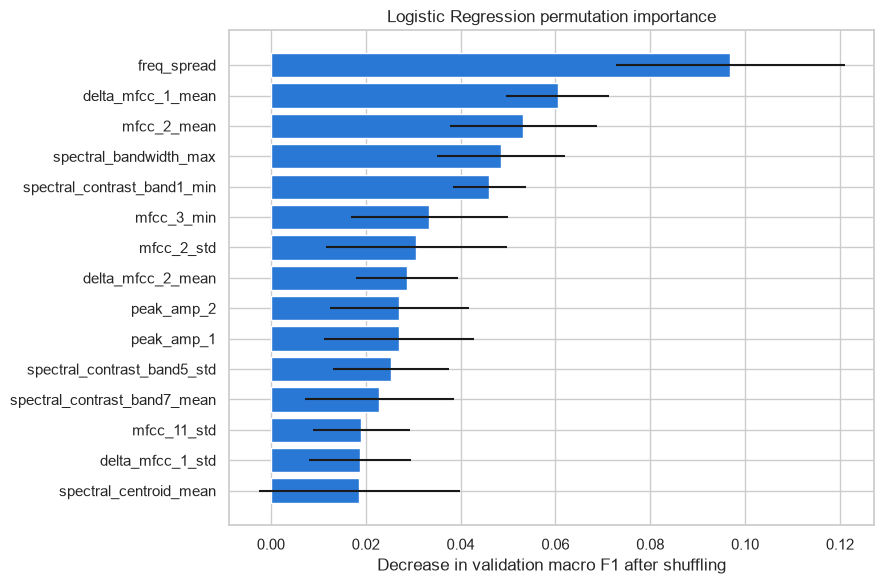

                     feature  mean_f1_drop  std_f1_drop
                 freq_spread      0.096877     0.024120
           delta_mfcc_1_mean      0.060453     0.010902
                 mfcc_2_mean      0.053250     0.015482
      spectral_bandwidth_max      0.048500     0.013512
 spectral_contrast_band1_min      0.046078     0.007776
                  mfcc_3_min      0.033435     0.016539
                  mfcc_2_std      0.030662     0.019063
           delta_mfcc_2_mean      0.028613     0.010756
                  peak_amp_2      0.027083     0.014643
                  peak_amp_1      0.026944     0.015817
 spectral_contrast_band5_std      0.025350     0.012257
spectral_contrast_band7_mean      0.022867     0.015739
                 mfcc_11_std      0.019100     0.010178
            delta_mfcc_1_std      0.018718     0.010739
      spectral_centroid_mean      0.018676     0.021288


In [33]:
permutation = permutation_importance(best_model, X_val_raw, y_val, scoring="f1_macro", n_repeats=10, random_state=RANDOM_SEED, n_jobs=-1)
permutation_df = pd.DataFrame({"feature": feature_cols, "mean_f1_drop": permutation.importances_mean, "std_f1_drop": permutation.importances_std}).sort_values("mean_f1_drop", ascending=False)
top = permutation_df.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6)); ax.barh(top["feature"], top["mean_f1_drop"], xerr=top["std_f1_drop"], color="#2a78d6"); ax.set_xlabel("Decrease in validation macro F1 after shuffling"); ax.set_title("Logistic Regression permutation importance"); fig.tight_layout(); fig.savefig("plots/logistic_permutation_importance.png", dpi=200); plt.show(); plt.close(fig)
print(permutation_df.head(15).to_string(index=False))


### 7.4 Error Analysis
Inspect minority-class recall, source-wise accuracy, confidence reliability, and the most confident test errors.

In [34]:
error_df = pd.DataFrame({"source_clip_id": df.loc[test_mask, "source_clip_id"].to_numpy(), "true": [classes[i] for i in y_test], "predicted": [classes[i] for i in test_pred], "confidence": test_prob.max(axis=1)})
meta_path = Path("../data/metadata/master_metadata.csv")
if meta_path.exists():
    metadata = pd.read_csv(meta_path)
    source_key = "clip_id" if "clip_id" in metadata.columns else "source_clip_id"
    source_map = dict(zip(metadata[source_key], metadata["source_dataset"])) if "source_dataset" in metadata.columns else {}
    error_df["source_dataset"] = error_df["source_clip_id"].map(source_map).fillna("Unknown source")
else:
    error_df["source_dataset"] = "Unknown source"
error_df["correct"] = error_df["true"].eq(error_df["predicted"])
print("Recall by true class:"); print(error_df.groupby("true")["correct"].mean())
print("Accuracy by source:"); print(error_df.groupby("source_dataset")["correct"].agg(["size", "mean"]))
print("Most confident errors:"); print(error_df.loc[~error_df["correct"]].sort_values("confidence", ascending=False).head(10))


Recall by true class:
true
ambient        0.850000
unknown        0.666667
vessel_like    0.984547
Name: correct, dtype: float64
Accuracy by source:
                size      mean
source_dataset                
DeepShip         398  0.984925
ShipsEar          42  0.952381
Synthetic         42  0.880952
Most confident errors:
    source_clip_id         true    predicted  confidence source_dataset  \
229   95955d3c-d13  vessel_like      ambient    0.999999       DeepShip   
24    94f1fb34-d9f      ambient  vessel_like    0.989077       ShipsEar   
4     4165cba0-672      ambient  vessel_like    0.966017       ShipsEar   
357   9acd7831-65c      unknown  vessel_like    0.926845      Synthetic   
449   c524a537-2e2  vessel_like      ambient    0.808534       DeepShip   
478   a360c231-6b6      ambient  vessel_like    0.797813      Synthetic   
445   c524a537-2e2  vessel_like      ambient    0.697695       DeepShip   
452   0d7e6fa3-cb1  vessel_like      unknown    0.695265      Synthetic  

##### 7.5 Probability Reliability Analysis

confidence_bin  segments  mean_confidence  accuracy       gap
 (-0.001, 0.6]         3         0.548036  0.000000  0.548036
    (0.6, 0.8]        11         0.699975  0.545455  0.154520
    (0.8, 0.9]        10         0.863632  0.900000 -0.036368
   (0.9, 0.95]         9         0.936917  0.888889  0.048028
   (0.95, 1.0]       449         0.996951  0.993318  0.003633


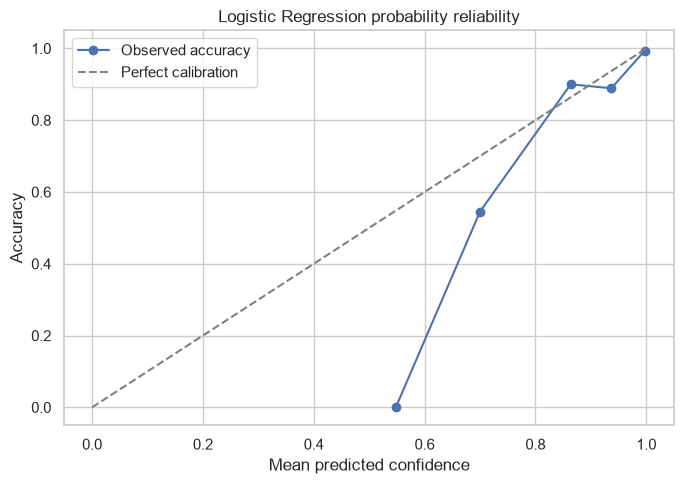

In [32]:
reliability = pd.DataFrame({"confidence": test_prob.max(axis=1), "correct": test_pred == y_test})
reliability["confidence_bin"] = pd.cut(reliability["confidence"], bins=[0, .6, .8, .9, .95, 1.0], include_lowest=True)
reliability_table = reliability.groupby("confidence_bin", observed=False).agg(segments=("correct", "size"), mean_confidence=("confidence", "mean"), accuracy=("correct", "mean")).reset_index()
reliability_table["gap"] = reliability_table["mean_confidence"] - reliability_table["accuracy"]
print(reliability_table.to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 5)); ax.plot(reliability_table["mean_confidence"], reliability_table["accuracy"], marker="o", label="Observed accuracy"); ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration"); ax.set_xlabel("Mean predicted confidence"); ax.set_ylabel("Accuracy"); ax.set_title("Logistic Regression probability reliability"); ax.legend(); fig.tight_layout(); fig.savefig("plots/logistic_probability_reliability.png", dpi=200); plt.show(); plt.close(fig)


## 8. Export Model Artifacts for Final Showdown

In [36]:
metrics_payload = {"algorithm": "Multinomial Logistic Regression", "slug": "logistic_regression", "best_hyperparameters": {key: (None if value is None else value) for key, value in best_params.items()}, "grouped_cv_macro_f1": best_cv_score, "validation": val_metrics, "test": test_metrics, "training_time_seconds": float(training_time_seconds), "prediction_time_seconds": float(prediction_time_seconds), "latency_ms": float(latency_ms), "classes": classes, "feature_count": len(feature_cols), "test_segments": len(X_test_raw)}
metadata_payload = {"algorithm": metrics_payload["algorithm"], "slug": metrics_payload["slug"], "feature_names": feature_cols, "feature_count": len(feature_cols), "classes": classes, "split_counts": split_counts.to_dict(), "best_hyperparameters": metrics_payload["best_hyperparameters"]}
joblib.dump(best_model, "models/model_logistic_regression.joblib")
joblib.dump(best_model.named_steps["scaler"], "models/scaler_logistic_regression.joblib")
joblib.dump(label_encoder, "models/label_encoder_logistic_regression.joblib")
Path("models/metrics_logistic_regression.json").write_text(json.dumps(metrics_payload, indent=2), encoding="utf-8")
Path("models/logistic_regression_metadata.json").write_text(json.dumps(metadata_payload, indent=2), encoding="utf-8")
print("Saved Logistic Regression model artifacts.")


Saved Logistic Regression model artifacts.


In [37]:
reloaded_model = joblib.load("models/model_logistic_regression.joblib")
reloaded_encoder = joblib.load("models/label_encoder_logistic_regression.joblib")
reloaded_pred = reloaded_model.predict(X_test_raw)
reloaded_prob = reloaded_model.predict_proba(X_test_raw)
assert np.array_equal(reloaded_pred, test_pred)
assert np.allclose(reloaded_prob, test_prob)
assert list(reloaded_encoder.classes_) == classes
print("Reloaded Logistic Regression reproduces test predictions and probabilities.")


Reloaded Logistic Regression reproduces test predictions and probabilities.


## 9. Conclusion

In [38]:
print("Selected parameters:", best_params)
print(f"Grouped CV macro F1: {best_cv_score:.4f}")
print(f"Validation macro F1: {val_metrics['macro_f1']:.4f}")
print(f"Held-out test macro F1: {test_metrics['macro_f1']:.4f}")
print(f"Held-out test accuracy: {test_metrics['accuracy']:.4f}")


Selected parameters: {'lr__C': 0.1, 'lr__class_weight': None}
Grouped CV macro F1: 0.9215
Validation macro F1: 0.9394
Held-out test macro F1: 0.8421
Held-out test accuracy: 0.9730
